---
# Exploración de los datos

## 1. Carga de datos y verificación train vs test

Primero cargamos las tablas de entrenamiento, los archivos de ejemplo en `test/` y `sample_submission.csv`, y verificamos qué columnas están disponibles al predecir y si los pozos de `test/` local se repiten en `train/`.

In [6]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datos.descargar import descargar
from datos.cargar import cargar_datos_csv as cargar

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

RAIZ = descargar()
train_hw = cargar(RAIZ, 'train', 'horizontal_well')
train_tw = cargar(RAIZ, 'train', 'typewell')
test_hw = cargar(RAIZ, 'test', 'horizontal_well')
test_tw = cargar(RAIZ, 'test', 'typewell')
sample_sub = pd.read_csv(RAIZ / 'sample_submission.csv')

for nombre, df in [
    ('train_hw', train_hw),
    ('train_tw', train_tw),
    ('test_hw', test_hw),
    ('test_tw', test_tw),
    ('sample_sub', sample_sub),
]:
    print(f'{nombre:10s}: {df.shape[0]:>9,} filas x {df.shape[1]:2d} cols')

train_hw  : 5,092,255 filas x 14 cols
train_tw  : 1,567,045 filas x  4 cols
test_hw   :    19,221 filas x  7 cols
test_tw   :     5,798 filas x  3 cols
sample_sub:    14,151 filas x  2 cols


In [7]:
# Comprobar relación entre train y el test local de ejemplo
train_ids = set(train_hw['well_id'].unique())
test_ids = set(test_hw['well_id'].unique())
print(f'Pozos en train: {len(train_ids)}')
print(f'Pozos en test local: {len(test_ids)} -> {sorted(test_ids)}')
print(f'¿Cuántos pozos de test local ya están en train?: {len(train_ids & test_ids)}')

# Comparar columnas y porcentajes de faltantes
faltantes_hw = pd.DataFrame({
    'train_%_NaN': (train_hw.isna().mean() * 100).round(2),
    'test_%_NaN': (test_hw.isna().mean() * 100).round(2),
    'en_test': train_hw.columns.isin(test_hw.columns),
}).sort_values(['en_test', 'train_%_NaN'], ascending=[False, False])

faltantes_tw = pd.DataFrame({
    'train_%_NaN': (train_tw.isna().mean() * 100).round(2),
    'test_%_NaN': (test_tw.isna().mean() * 100).round(2),
    'en_test': train_tw.columns.isin(test_tw.columns),
}).sort_values(['en_test', 'train_%_NaN'], ascending=[False, False])

print('\n--- horizontal_well ---')
display(faltantes_hw)
print('\n--- typewell ---')
display(faltantes_tw)

Pozos en train: 773
Pozos en test local: 3 -> ['000d7d20', '00bbac68', '00e12e8b']
¿Cuántos pozos de test local ya están en train?: 3

--- horizontal_well ---


,train_%_NaN,test_%_NaN,en_test
ANCC,0.90,NaN,True
ASTNL,0.00,NaN,True
ASTNU,0.00,NaN,True
BUDA,0.00,NaN,True
Y,0.00,0.00,True
Z,0.00,0.00,True
well_id,0.00,0.00,True
TVT_input,74.31,73.62,False
GR,29.61,19.69,False
EGFDL,0.12,NaN,False



--- typewell ---


,train_%_NaN,test_%_NaN,en_test
Geology,33.41,NaN,True
GR,0.00,0.0,True
well_id,0.00,0.0,True
TVT,0.00,0.0,False


### Resultados clave de integridad (`train` vs `test`)

1. **Los 3 pozos en `test/` local son ejemplos tomados del propio `train/`** (`000d7d20`, `00bbac68`, `00e12e8b`), tal como advierte la documentación de Kaggle. El conjunto real de evaluación (~200 pozos) es oculto. Por eso, **no debemos sacar conclusiones estadísticas de `test/` local ni usarlo para validar**, solo para verificar que nuestro código genera un `submission.csv` válido.
2. **Columnas que NO existen en prueba:**
   - En `horizontal_well`: faltan `TVT` (la variable objetivo) y las 6 cimas geológicas (`ANCC`, `ASTNU`, `ASTNL`, `EGFDU`, `EGFDL`, `BUDA`).
   - En `typewell`: falta la columna `Geology` (además, en entrenamiento tiene 33.4 % de vacíos).
   - *Decisión:* ningún atributo del modelo puede depender de `Geology` ni de las 6 cimas; solo sirven para entender los datos o como objetivos auxiliares durante entrenamiento.
3. **Coordenadas y `typewell` completos:** `MD`, `X`, `Y`, `Z` en `horizontal_well` y `TVT`, `GR` en `typewell` tienen **0 % de faltantes**. Solo `GR` del pozo horizontal (29.6 % en `train`) y `TVT_input` (74.3 %, que define la zona a predecir) tienen vacíos.

## 2. Estructura de cada pozo y desbalance en el RMSE

**Preguntas concretas:**
- ¿El corte de *Prediction Start* (PS) es siempre limpio (todo conocido al inicio y todo vacío después), o hay tramos intermitentes?
- ¿La distancia medida `MD` siempre avanza de 1 en 1 pie?
- ¿Qué tanto varía el largo de la zona a predecir entre pozos y cuánto pesan los más largos en el RMSE?

In [8]:
# Calcular métricas por pozo en train (se reutiliza en las siguientes secciones)
tw_dict = {
    wid: (g['TVT'].to_numpy(), g['GR'].to_numpy())
    for wid, g in train_tw.groupby('well_id', sort=False)
}

resumen_pozos = []
longitudes_huecos_eval = []

for wid, g in train_hw.groupby('well_id', sort=False):
    es_eval = g['TVT_input'].isna().to_numpy()
    n_total = len(g)
    n_eval = int(es_eval.sum())
    n_conocido = n_total - n_eval
    primer_na = int(np.argmax(es_eval)) if n_eval > 0 else n_total
    corte_limpio = (not es_eval[:primer_na].any()) and es_eval[primer_na:].all()

    md_diffs = np.diff(g['MD'].to_numpy())
    paso_unico = bool(np.allclose(md_diffs, 1.0))

    # Faltantes de GR antes y después de PS
    gr_pre_na = float(g['GR'].iloc[:primer_na].isna().mean() * 100)
    gr_post_na = float(g['GR'].iloc[primer_na:].isna().mean() * 100)

    # Longitud de cada hueco consecutivo de GR en la zona de evaluación
    gr_ev_na = g['GR'].iloc[primer_na:].isna().to_numpy()
    padded = np.concatenate(([False], gr_ev_na, [False]))
    inicios = np.where(padded[1:] & ~padded[:-1])[0]
    fines = np.where(~padded[1:] & padded[:-1])[0]
    huecos = fines - inicios
    if len(huecos) > 0:
        longitudes_huecos_eval.extend(huecos.tolist())
        max_hueco = int(huecos.max())
    else:
        max_hueco = 0

    # Comportamiento de TVT, Z y geometría desde PS hasta el final
    tvt_ps = float(g['TVT'].iloc[primer_na - 1])
    z_ps = float(g['Z'].iloc[primer_na - 1])
    dtvt = g['TVT'].iloc[primer_na:].to_numpy() - tvt_ps
    dz = g['Z'].iloc[primer_na:].to_numpy() - z_ps

    rmse_const = float(np.sqrt(np.mean(dtvt ** 2)))
    rmse_plano = float(np.sqrt(np.mean((dtvt - (-dz)) ** 2)))

    dx = float(g['X'].iloc[-1] - g['X'].iloc[primer_na - 1])
    dy = float(g['Y'].iloc[-1] - g['Y'].iloc[primer_na - 1])
    dz_tot = float(dz[-1])
    dist_h = float(np.hypot(dx, dy))
    azimut = float(np.degrees(np.arctan2(dx, dy)) % 360)
    # Pendiente aparente de las capas a lo largo del pozo (en pies por cada 100 pies horizontales)
    pendiente_capas = float((dz_tot + dtvt[-1]) / max(dist_h, 1.0) * 100)

    # Correlación y sesgo entre GR horizontal y GR del typewell en la zona conocida
    tvt_tw, gr_tw = tw_dict[wid]
    conocidos_gr = g.iloc[:primer_na].dropna(subset=['GR'])
    if len(conocidos_gr) >= 30:
        gr_tw_interp = np.interp(conocidos_gr['TVT'].to_numpy(), tvt_tw, gr_tw)
        corr_gr = float(np.corrcoef(conocidos_gr['GR'].to_numpy(), gr_tw_interp)[0, 1])
        sesgo_gr = float(conocidos_gr['GR'].mean() - gr_tw_interp.mean())
    else:
        corr_gr, sesgo_gr = np.nan, np.nan

    resumen_pozos.append({
        'well_id': wid,
        'n_total': n_total,
        'n_conocido': n_conocido,
        'n_eval': n_eval,
        'pct_eval': n_eval / n_total * 100,
        'corte_limpio': corte_limpio,
        'paso_1ft': paso_unico,
        'gr_pre_na': gr_pre_na,
        'gr_post_na': gr_post_na,
        'max_hueco_gr': max_hueco,
        'tvt_rango_eval': float(dtvt.max() - dtvt.min()),
        'tvt_cambio_neto': float(dtvt[-1]),
        'rmse_const': rmse_const,
        'rmse_plano': rmse_plano,
        'x_ps': float(g['X'].iloc[primer_na - 1]),
        'y_ps': float(g['Y'].iloc[primer_na - 1]),
        'azimut': azimut,
        'pendiente_capas_100ft': pendiente_capas,
        'corr_gr_pre': corr_gr,
        'sesgo_gr_pre': sesgo_gr,
    })

pozos = pd.DataFrame(resumen_pozos)
huecos_gr = pd.Series(longitudes_huecos_eval)

print('¿Todos los pozos tienen corte PS limpio?:', pozos['corte_limpio'].all())
print('¿Todos los pozos avanzan exactamente de 1 en 1 pie en MD?:', pozos['paso_1ft'].all())
print('¿TVT y TVT_input coinciden exactamente antes de PS?:',
      np.allclose(train_hw.loc[train_hw['TVT_input'].notna(), 'TVT'],
                  train_hw.loc[train_hw['TVT_input'].notna(), 'TVT_input']))
print('¿sample_sub coincide con el total de NaN en test_hw?:',
      len(sample_sub) == int(test_hw['TVT_input'].isna().sum()))

pozos[['n_total', 'n_conocido', 'n_eval', 'pct_eval']].describe().round(1)

¿Todos los pozos tienen corte PS limpio?: True
¿Todos los pozos avanzan exactamente de 1 en 1 pie en MD?: True
¿TVT y TVT_input coinciden exactamente antes de PS?: True
¿sample_sub coincide con el total de NaN en test_hw?: True


,n_total,n_conocido,n_eval,pct_eval
count,773.0,773.0,773.0,773.0
mean,6587.7,1692.5,4895.2,73.3
std,1311.5,217.3,1301.2,6.4
min,2058.0,851.0,407.0,19.8
25%,5706.0,1546.0,4044.0,70.0
50%,6576.0,1703.0,4840.0,74.0
75%,7388.0,1839.0,5694.0,77.5
max,12141.0,2392.0,10052.0,87.5


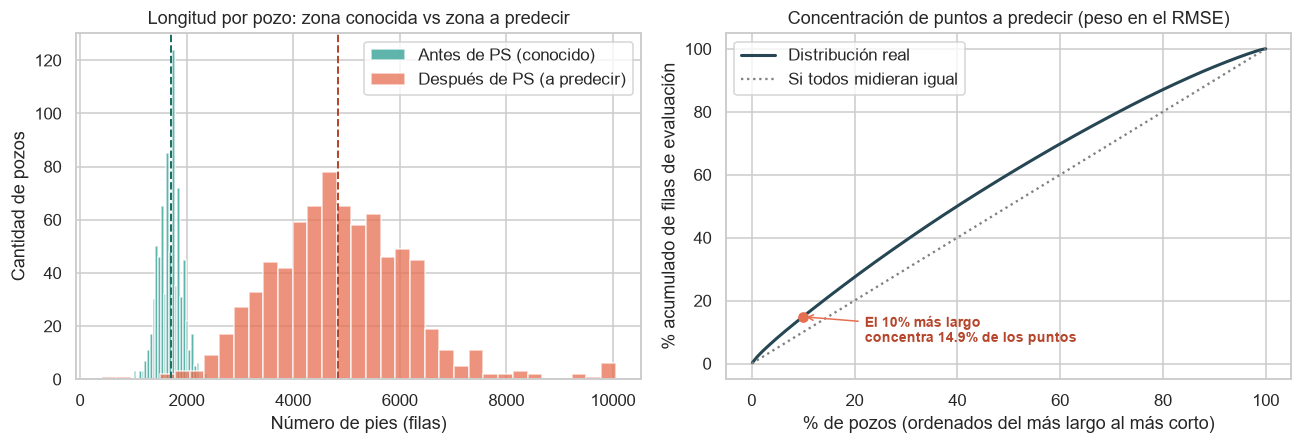

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Panel 1: Distribución de longitudes antes y después de PS
axes[0].hist(pozos['n_conocido'], bins=30, alpha=0.75, label='Antes de PS (conocido)', color='#2a9d8f')
axes[0].hist(pozos['n_eval'], bins=35, alpha=0.75, label='Después de PS (a predecir)', color='#e76f51')
axes[0].axvline(pozos['n_conocido'].median(), color='#1d6f65', linestyle='--', linewidth=1.3)
axes[0].axvline(pozos['n_eval'].median(), color='#b5462b', linestyle='--', linewidth=1.3)
axes[0].set_title('Longitud por pozo: zona conocida vs zona a predecir')
axes[0].set_xlabel('Número de pies (filas)')
axes[0].set_ylabel('Cantidad de pozos')
axes[0].legend()

# Panel 2: Peso acumulado en el RMSE según el largo del pozo
orden_eval = pozos['n_eval'].sort_values(ascending=False).to_numpy()
peso_acum = np.cumsum(orden_eval) / orden_eval.sum() * 100
pct_pozos = np.arange(1, len(orden_eval) + 1) / len(orden_eval) * 100

top10_peso = peso_acum[int(len(orden_eval) * 0.10) - 1]
axes[1].plot(pct_pozos, peso_acum, color='#264653', linewidth=2, label='Distribución real')
axes[1].plot([0, 100], [0, 100], color='gray', linestyle=':', label='Si todos midieran igual')
axes[1].scatter([10], [top10_peso], color='#e76f51', zorder=5)
axes[1].annotate(
    f'El 10% más largo\nconcentra {top10_peso:.1f}% de los puntos',
    xy=(10, top10_peso), xytext=(22, top10_peso - 8),
    arrowprops=dict(arrowstyle='->', color='#e76f51'),
    fontsize=9, color='#b5462b', fontweight='bold'
)
axes[1].set_title('Concentración de puntos a predecir (peso en el RMSE)')
axes[1].set_xlabel('% de pozos (ordenados del más largo al más corto)')
axes[1].set_ylabel('% acumulado de filas de evaluación')
axes[1].legend()

plt.tight_layout()
plt.show()

### Conclusiones de la sección 2

- **Estructura muy limpia:** en los 773 pozos, `MD` avanza exactamente de **1 en 1 pie** y el corte de *Prediction Start* es siempre continuo (primero todo conocido, luego todo a predecir). Además, antes de PS `TVT_input` es idéntico a `TVT`.
- **Desbalance moderado por longitud:** la zona conocida es bastante parecida entre pozos (mediana ~1,703 pies), pero la zona a predecir va de **407 a 10,052 pies** (casi 25× de diferencia). El 10 % de pozos más largos aporta casi el **15 % de todos los puntos** del RMSE.
- **Implicación para la validación:** nunca debemos dividir aleatoriamente por filas (habría fuga masiva entre pies vecinos del mismo pozo). La partición debe hacerse **por pozo completo**, evaluando el RMSE concatenando todos los puntos de evaluación (como Kaggle) y revisando también el error por pozo para detectar casos extremos.

## 3. Faltantes en rayos gamma (`GR`): ¿pozos vacíos o huecos cortos?

Sabemos que en `train_hw` falta casi el 30 % de `GR`. Antes de decidir cómo imputar o usar esta señal, respondemos dos preguntas:
- ¿Hay pozos completamente sin `GR`, o los faltantes están repartidos en todos los pozos?
- ¿Son bloques largos sin medición o pausas cortas de unos pocos pies?

Pozos con 0% de GR faltante en evaluación: 0
Pozos con >50% de GR faltante en evaluación: 188 (24.3%)
Pozos con 100% de GR faltante en evaluación: 0
Huecos de exactamente 1 pie: 61.6%
Huecos de 5 pies o menos: 95.7% (representan 81.1% de todos los NaN)
Hueco máximo típico por pozo (mediana): 11 pies (máximo global: 263 pies)


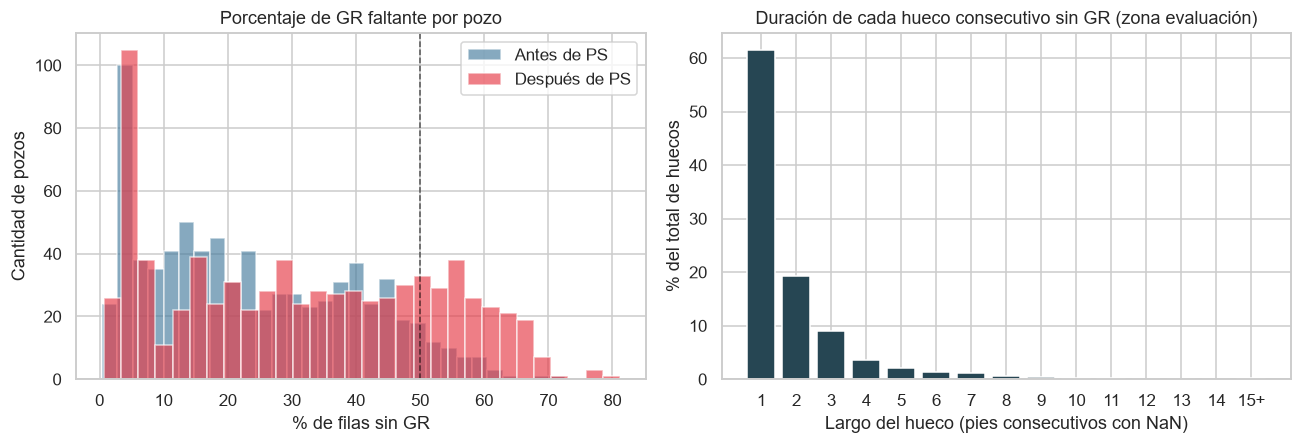

In [10]:
print(f'Pozos con 0% de GR faltante en evaluación: {(pozos["gr_post_na"] == 0).sum()}')
print(f'Pozos con >50% de GR faltante en evaluación: {(pozos["gr_post_na"] > 50).sum()} ({(pozos["gr_post_na"] > 50).mean()*100:.1f}%)')
print(f'Pozos con 100% de GR faltante en evaluación: {(pozos["gr_post_na"] >= 99.9).sum()}')
print(f'Huecos de exactamente 1 pie: {(huecos_gr == 1).mean()*100:.1f}%')
print(f'Huecos de 5 pies o menos: {(huecos_gr <= 5).mean()*100:.1f}% (representan {huecos_gr[huecos_gr <= 5].sum() / huecos_gr.sum() * 100:.1f}% de todos los NaN)')
print(f'Hueco máximo típico por pozo (mediana): {pozos["max_hueco_gr"].median():.0f} pies (máximo global: {pozos["max_hueco_gr"].max()} pies)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Panel 1: % de GR faltante por pozo antes vs después de PS
axes[0].hist(pozos['gr_pre_na'], bins=30, alpha=0.65, label='Antes de PS', color='#457b9d')
axes[0].hist(pozos['gr_post_na'], bins=30, alpha=0.65, label='Después de PS', color='#e63946')
axes[0].axvline(50, color='black', linestyle='--', linewidth=1, alpha=0.6)
axes[0].set_title('Porcentaje de GR faltante por pozo')
axes[0].set_xlabel('% de filas sin GR')
axes[0].set_ylabel('Cantidad de pozos')
axes[0].legend()

# Panel 2: Tamaño de los huecos consecutivos en la zona de evaluación (recortado a 15 pies)
conteo_huecos = huecos_gr.clip(upper=15).value_counts().sort_index()
etiquetas = [str(k) if k < 15 else '15+' for k in conteo_huecos.index]
axes[1].bar(etiquetas, conteo_huecos.values / len(huecos_gr) * 100, color='#264653')
axes[1].set_title('Duración de cada hueco consecutivo sin GR (zona evaluación)')
axes[1].set_xlabel('Largo del hueco (pies consecutivos con NaN)')
axes[1].set_ylabel('% del total de huecos')

plt.tight_layout()
plt.show()

### Conclusiones de la sección 3

- **Ningún pozo está completamente vacío de `GR`**, pero el porcentaje faltante varía muchísimo: casi 1 de cada 4 pozos (24.3 %) tiene más de la mitad de `GR` vacío después del PS (y faltan más datos después del PS que antes: 31.5 % vs 23.6 % en promedio).
- **Hallazgo clave sobre el patrón de faltantes:** más del **61 % de los huecos miden solo 1 pie** y el **95.7 % miden 5 pies o menos** (eso concentra el 81 % de todos los `NaN`). Es decir, en su gran mayoría no son fallas largas sino lecturas tomadas cada pocos pies.
- **Implicación para atributos:**
  1. Interpolar linealmente `GR` en huecos cortos (por ejemplo, hasta ~10 pies) recupera casi toda la señal sin inventar valores en huecos largos.
  2. Guardar una bandera binaria (`GR_isna`) o la densidad de mediciones permite al modelo saber cuándo un dato fue medido y cuándo fue interpolado.
  3. Aun así, como hay pozos con hasta 81 % de `GR` faltante, el modelo **no puede depender solo de `GR`** y debe apoyarse también en la trayectoria y los pozos vecinos.

## 4. Distribuciones de `GR`, `TVT` y comportamiento geométrico

**Preguntas concretas:**
- ¿Hay valores anómalos en `GR` y coincide su rango entre el pozo horizontal y el `typewell`?
- ¿Cuánto se mueve realmente el `TVT` después del *Prediction Start*?
- ¿Qué error obtenemos si predecimos lo más simple: dejar `TVT` constante vs asumir que las capas son planas y solo seguir la profundidad `Z`?

GR horizontal -> min: 13.9, mediana: 85.9, p99: 154.8, max: 487.0 (>300 API: 11 filas)
GR typewell   -> min: 18.5, mediana: 89.7, p99: 184.9, max: 433.6 (>300 API: 97 filas)
Rango típico de TVT en zona evaluación (mediana): 26.4 pies
RMSE global (TVT constante = TVT_PS):             15.91 pies
RMSE global (capas planas = TVT_PS - dZ):         107.49 pies


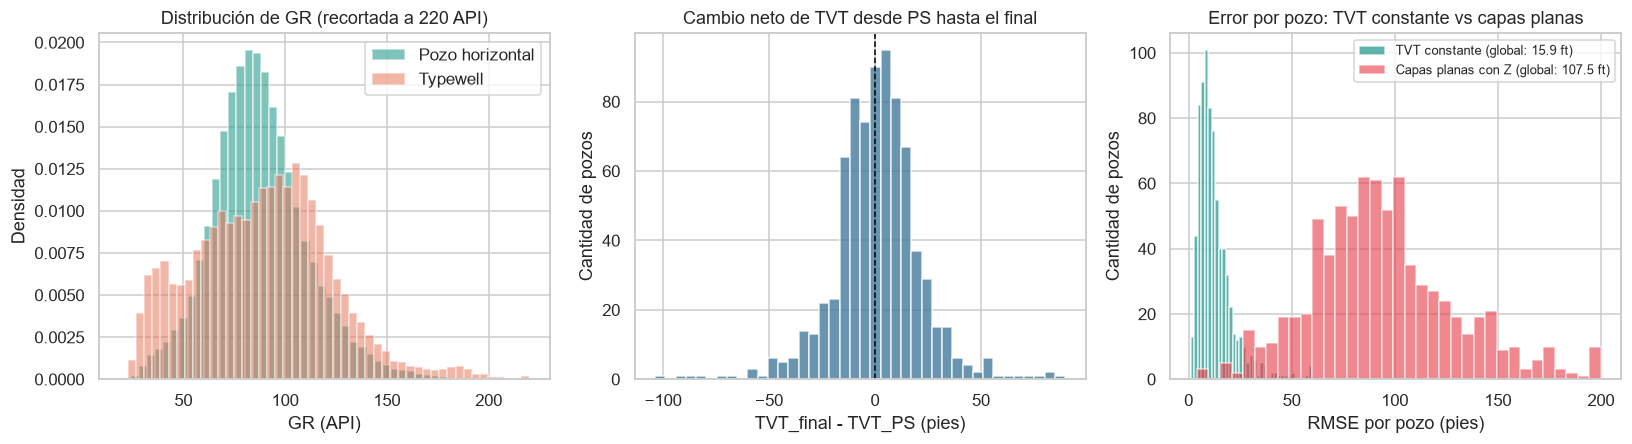

In [11]:
# RMSE global (exactamente como evalúa Kaggle: concatenando todos los puntos de evaluación)
ev_mask = train_hw['TVT_input'].isna()
tvt_ps_serie = train_hw.groupby('well_id')['TVT_input'].transform('ffill')
z_ps_serie = train_hw['Z'].where(train_hw['TVT_input'].notna()).groupby(train_hw['well_id']).ffill()

y_real = train_hw.loc[ev_mask, 'TVT'].to_numpy()
y_const = tvt_ps_serie.loc[ev_mask].to_numpy()
y_plano = (tvt_ps_serie - (train_hw['Z'] - z_ps_serie)).loc[ev_mask].to_numpy()

rmse_global_const = float(np.sqrt(np.mean((y_real - y_const) ** 2)))
rmse_global_plano = float(np.sqrt(np.mean((y_real - y_plano) ** 2)))

print(f'GR horizontal -> min: {train_hw["GR"].min():.1f}, mediana: {train_hw["GR"].median():.1f}, p99: {train_hw["GR"].quantile(0.99):.1f}, max: {train_hw["GR"].max():.1f} (>300 API: {(train_hw["GR"] > 300).sum()} filas)')
print(f'GR typewell   -> min: {train_tw["GR"].min():.1f}, mediana: {train_tw["GR"].median():.1f}, p99: {train_tw["GR"].quantile(0.99):.1f}, max: {train_tw["GR"].max():.1f} (>300 API: {(train_tw["GR"] > 300).sum()} filas)')
print(f'Rango típico de TVT en zona evaluación (mediana): {pozos["tvt_rango_eval"].median():.1f} pies')
print(f'RMSE global (TVT constante = TVT_PS):             {rmse_global_const:.2f} pies')
print(f'RMSE global (capas planas = TVT_PS - dZ):         {rmse_global_plano:.2f} pies')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# Panel 1: Distribución de GR (horizontal vs typewell)
gr_hw_muestra = train_hw['GR'].dropna().clip(upper=220).sample(150_000, random_state=42)
gr_tw_muestra = train_tw['GR'].dropna().clip(upper=220).sample(150_000, random_state=42)
axes[0].hist(gr_hw_muestra, bins=50, density=True, alpha=0.6, label='Pozo horizontal', color='#2a9d8f')
axes[0].hist(gr_tw_muestra, bins=50, density=True, alpha=0.5, label='Typewell', color='#e76f51')
axes[0].set_title('Distribución de GR (recortada a 220 API)')
axes[0].set_xlabel('GR (API)')
axes[0].set_ylabel('Densidad')
axes[0].legend()

# Panel 2: Cambio total y rango de TVT en la zona de evaluación
axes[1].hist(pozos['tvt_cambio_neto'], bins=40, alpha=0.8, color='#457b9d')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Cambio neto de TVT desde PS hasta el final')
axes[1].set_xlabel('TVT_final - TVT_PS (pies)')
axes[1].set_ylabel('Cantidad de pozos')

# Panel 3: RMSE por pozo de las dos ideas simples
axes[2].hist(pozos['rmse_const'].clip(upper=60), bins=35, alpha=0.75, label=f'TVT constante (global: {rmse_global_const:.1f} ft)', color='#2a9d8f')
axes[2].hist(pozos['rmse_plano'].clip(upper=200), bins=35, alpha=0.6, label=f'Capas planas con Z (global: {rmse_global_plano:.1f} ft)', color='#e63946')
axes[2].set_title('Error por pozo: TVT constante vs capas planas')
axes[2].set_xlabel('RMSE por pozo (pies)')
axes[2].set_ylabel('Cantidad de pozos')
axes[2].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

### Conclusiones de la sección 4

- **Sin valores negativos y casi sin outliers extremos en `GR`:** en ambos archivos `GR` está concentrado entre 30 y 180 API (solo hay 11 mediciones > 300 API en 3.58 millones de filas de `train_hw`). Un recorte suave (por ejemplo en ~250–300 API) evita que picos aislados distorsionen modelos sensibles a la escala.
- **El `typewell` tiene mayor dispersión que el pozo horizontal:** es lógico porque el pozo vertical atraviesa todas las capas geológicas (desde las más bajas hasta las más altas en `GR`), mientras que el pozo horizontal intenta quedarse dentro de la misma zona objetivo.
- **Gran sorpresa geométrica (y excelente referencia para línea base):**
  - Suponer capas planas (`TVT = TVT_PS - ΔZ`) da un error enorme (**107.5 pies**), lo que prueba que **las capas de roca están fuertemente inclinadas** y el perforador sube o baja siguiendo esa pendiente.
  - En cambio, simplemente mantener `TVT` constante igual al último valor conocido en PS logra **15.91 pies** de RMSE global, porque el pozo intenta navegar dentro de la misma capa (el rango típico de `TVT` en ~4,840 pies de recorrido es de apenas 26 pies).
- **Implicación para el modelado:** conviene predecir el **cambio respecto al punto inicial** ($\Delta \text{TVT} = \text{TVT} - \text{TVT}_{\text{PS}}$) en lugar del valor absoluto de `TVT` (que anda por ~10,000–13,000 pies), y `TVT` constante (15.91 pies) es el piso mínimo que cualquier modelo debe superar por amplio margen.

## 5. Ubicación geográfica, dirección del pozo e inclinación de las capas

Según la documentación de la competencia, los pozos cercanos que perforan en la misma dirección (azimut) comparten la inclinación geológica (*dip*) de las capas, y los pozos de prueba están intercalados geográficamente con los de entrenamiento.

**Preguntas concretas:**
- ¿Cómo se distribuyen los 773 pozos en el mapa `(X, Y)`?
- ¿En qué direcciones se perforan y cómo cambia la inclinación aparente de las capas según la dirección y la ubicación?

Pozos perforados hacia el Noroeste (270°–360°): 397 (51.4%) | pendiente media: +3.54 ft / 100 ft
Pozos perforados hacia el Sureste  ( 90°–180°): 298 (38.6%) | pendiente media: -3.26 ft / 100 ft
Otras direcciones:                              78 (10.1%)


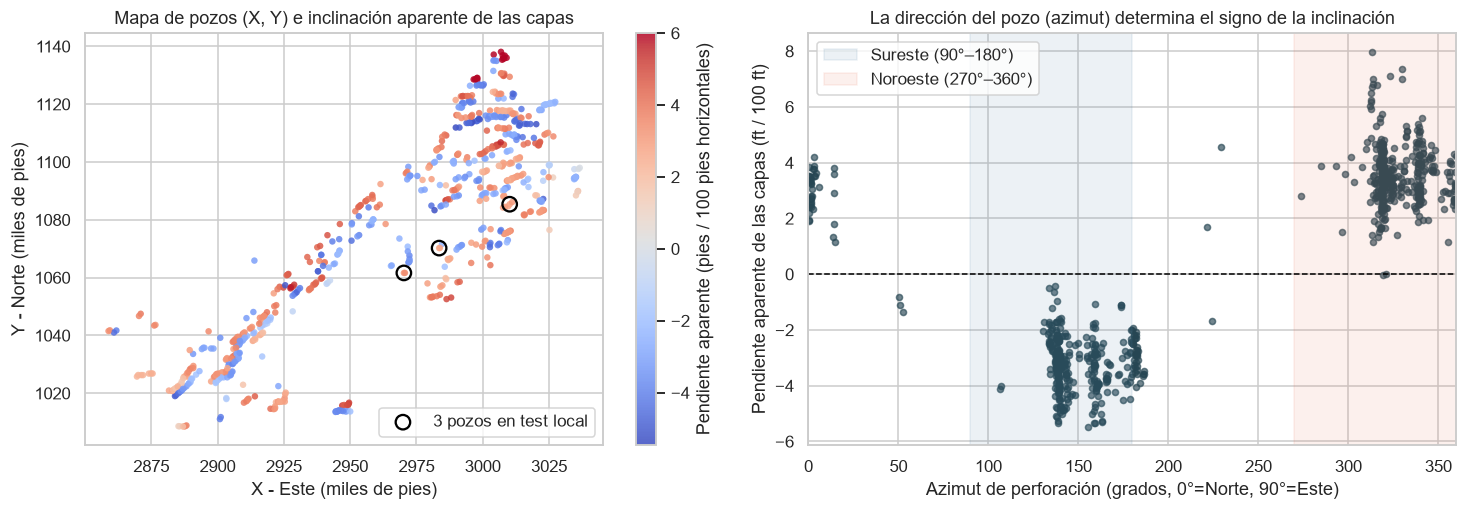

In [12]:
nw = (pozos['azimut'] >= 270) & (pozos['azimut'] <= 360)
se = (pozos['azimut'] >= 90) & (pozos['azimut'] <= 180)
print(f'Pozos perforados hacia el Noroeste (270°–360°): {nw.sum()} ({nw.mean()*100:.1f}%) | pendiente media: {pozos.loc[nw, "pendiente_capas_100ft"].mean():+.2f} ft / 100 ft')
print(f'Pozos perforados hacia el Sureste  ( 90°–180°): {se.sum()} ({se.mean()*100:.1f}%) | pendiente media: {pozos.loc[se, "pendiente_capas_100ft"].mean():+.2f} ft / 100 ft')
print(f'Otras direcciones:                              {(~(nw | se)).sum()} ({(~(nw | se)).mean()*100:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Panel 1: Mapa espacial (X, Y) coloreado por pendiente aparente de las capas
sc = axes[0].scatter(
    pozos['x_ps'] / 1000, pozos['y_ps'] / 1000,
    c=pozos['pendiente_capas_100ft'].clip(-6, 6),
    cmap='coolwarm', s=18, alpha=0.85, edgecolor='none'
)
# Marcar los 3 pozos de ejemplo en test local
ej_test = pozos[pozos['well_id'].isin(test_ids)]
axes[0].scatter(
    ej_test['x_ps'] / 1000, ej_test['y_ps'] / 1000,
    facecolors='none', edgecolors='black', s=90, linewidths=1.5, label='3 pozos en test local'
)
cbar = plt.colorbar(sc, ax=axes[0])
cbar.set_label('Pendiente aparente (pies / 100 pies horizontales)')
axes[0].set_title('Mapa de pozos (X, Y) e inclinación aparente de las capas')
axes[0].set_xlabel('X - Este (miles de pies)')
axes[0].set_ylabel('Y - Norte (miles de pies)')
axes[0].legend(loc='lower right')

# Panel 2: Pendiente aparente vs Azimut (dirección de perforación)
axes[1].scatter(pozos['azimut'], pozos['pendiente_capas_100ft'], s=16, alpha=0.65, color='#264653')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].axvspan(90, 180, color='#457b9d', alpha=0.10, label='Sureste (90°–180°)')
axes[1].axvspan(270, 360, color='#e76f51', alpha=0.10, label='Noroeste (270°–360°)')
axes[1].set_title('La dirección del pozo (azimut) determina el signo de la inclinación')
axes[1].set_xlabel('Azimut de perforación (grados, 0°=Norte, 90°=Este)')
axes[1].set_ylabel('Pendiente aparente de las capas (ft / 100 ft)')
axes[1].set_xlim(0, 360)
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

### Conclusiones de la sección 5

- **Patrón direccional clarísimo:** el **90 % de los pozos** se perforan en dos direcciones casi opuestas:
  - Hacia el **Noroeste (~315°)**: las capas suben en promedio **+3.5 pies por cada 100 pies** horizontales.
  - Hacia el **Sureste (~135°)**: las capas bajan en promedio **-3.3 pies por cada 100 pies** horizontales (el signo opuesto).
- **Coherencia espacial:** en el mapa `(X, Y)` se ven zonas donde los pozos cercanos perforan con orientaciones y pendientes muy consistentes. Esto confirma el primer punto de la documentación técnica: **la inclinación regional es predecible a partir de la posición `(X, Y)` y la dirección `(dX, dY, dZ, azimut)`**.
- **Implicaciones directas:**
  - *Para atributos:* incluir dirección de perforación (`dX`, `dY`, `dZ`, seno/coseno del azimut) y la inclinación promedio de los **pozos vecinos más cercanos** (*offset wells*). Eso sí: al usar vecinos en entrenamiento, hay que calcularlos **solo con los pozos del conjunto de entrenamiento de cada *fold*** para no filtrar respuestas.
  - *Para validación:* como el conjunto real de prueba está intercalado geográficamente dentro de la misma región, una validación cruzada **K-Fold agrupada por pozo** imita mejor la competencia que aislar regiones enteras (y permite probar con rigor si los atributos de vecinos realmente generalizan).

## 6. Señal de `GR` frente al *typewell* y ejemplos de pozos reales

Por último, revisamos qué tan bien se parece el `GR` del pozo horizontal al `GR` del pozo de referencia en la parte conocida (antes de PS), y visualizamos dos pozos reales con comportamientos opuestos: uno que navega casi estable dentro de una capa y otro que sube y baja cruzando varias capas.

Correlación GR horizontal vs typewell (antes de PS) -> mediana: 0.814 (25%: 0.755, 75%: 0.864)
Diferencia media de nivel (sesgo GR_hw - GR_tw)     -> rango: [-17.8, 13.4] API


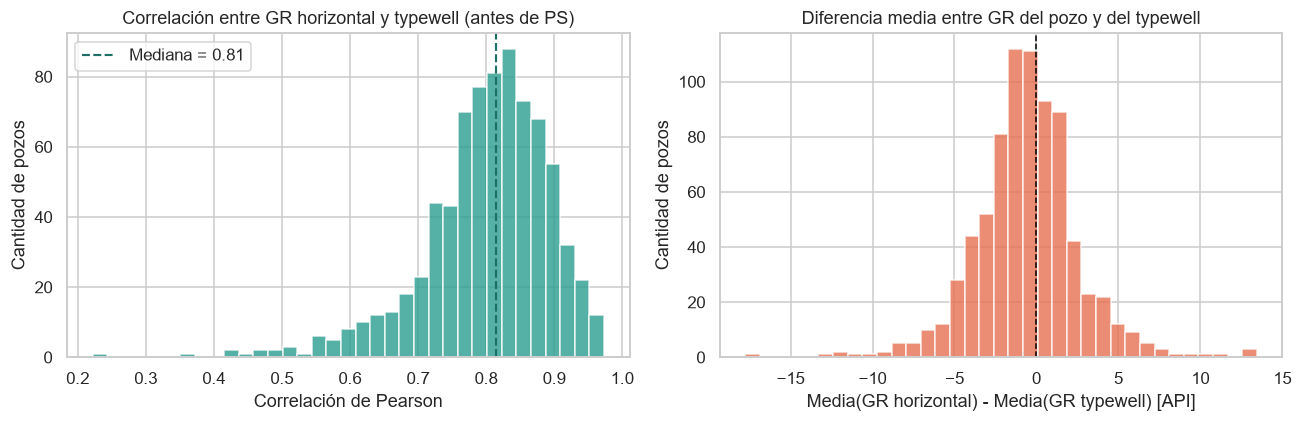

In [13]:
print(f'Correlación GR horizontal vs typewell (antes de PS) -> mediana: {pozos["corr_gr_pre"].median():.3f} (25%: {pozos["corr_gr_pre"].quantile(0.25):.3f}, 75%: {pozos["corr_gr_pre"].quantile(0.75):.3f})')
print(f'Diferencia media de nivel (sesgo GR_hw - GR_tw)     -> rango: [{pozos["sesgo_gr_pre"].min():.1f}, {pozos["sesgo_gr_pre"].max():.1f}] API')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))

axes[0].hist(pozos['corr_gr_pre'].dropna(), bins=35, color='#2a9d8f', alpha=0.8)
axes[0].axvline(pozos['corr_gr_pre'].median(), color='#1d6f65', linestyle='--', linewidth=1.4,
                label=f'Mediana = {pozos["corr_gr_pre"].median():.2f}')
axes[0].set_title('Correlación entre GR horizontal y typewell (antes de PS)')
axes[0].set_xlabel('Correlación de Pearson')
axes[0].set_ylabel('Cantidad de pozos')
axes[0].legend()

axes[1].hist(pozos['sesgo_gr_pre'].dropna(), bins=35, color='#e76f51', alpha=0.8)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Diferencia media entre GR del pozo y del typewell')
axes[1].set_xlabel('Media(GR horizontal) - Media(GR typewell) [API]')
axes[1].set_ylabel('Cantidad de pozos')

plt.tight_layout()
plt.show()

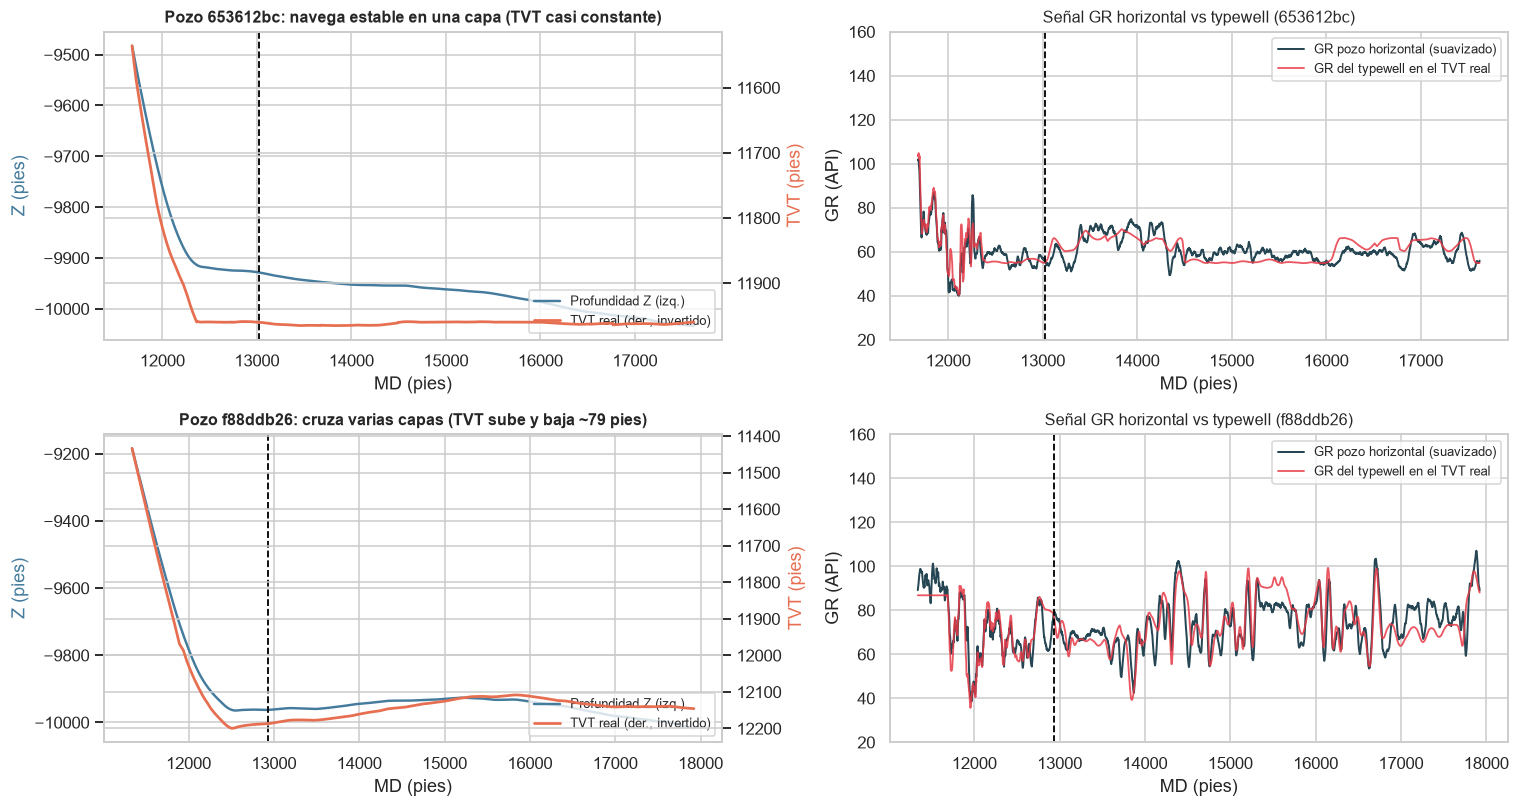

In [14]:
# Visualizar 2 pozos reales: uno estable en una capa y otro cruzando varias capas
ejemplos = [
    ('653612bc', 'Pozo 653612bc: navega estable en una capa (TVT casi constante)'),
    ('f88ddb26', 'Pozo f88ddb26: cruza varias capas (TVT sube y baja ~79 pies)'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))

for fila, (wid, titulo) in enumerate(ejemplos):
    g = train_hw[train_hw['well_id'] == wid].reset_index(drop=True)
    tw = train_tw[train_tw['well_id'] == wid]
    ps_idx = int(np.argmax(g['TVT_input'].isna().to_numpy()))
    md_ps = g.loc[ps_idx, 'MD']

    # Columna izquierda: trayectoria Z (profundidad real) y TVT (posición en las capas)
    ax1 = axes[fila, 0]
    ax1_r = ax1.twinx()

    l1, = ax1.plot(g['MD'], g['Z'], color='#457b9d', linewidth=1.6, label='Profundidad Z (izq.)')
    l2, = ax1_r.plot(g['MD'], g['TVT'], color='#e76f51', linewidth=1.8, label='TVT real (der., invertido)')
    ax1.axvline(md_ps, color='black', linestyle='--', linewidth=1.2, label='Prediction Start (PS)')
    ax1_r.invert_yaxis()  # TVT más grande = más profundo, igual que Z más negativo

    ax1.set_title(titulo, fontsize=10.5, fontweight='bold')
    ax1.set_xlabel('MD (pies)')
    ax1.set_ylabel('Z (pies)', color='#457b9d')
    ax1_r.set_ylabel('TVT (pies)', color='#e76f51')
    ax1.legend(handles=[l1, l2], loc='lower right', fontsize=8.5)

    # Columna derecha: señal GR horizontal vs GR esperado del typewell en la zona a predecir
    ax2 = axes[fila, 1]
    gr_tw_esperado = np.interp(g['TVT'].to_numpy(), tw['TVT'].to_numpy(), tw['GR'].to_numpy())
    # Suavizado ligero solo para facilitar la lectura visual
    gr_hw_suave = g['GR'].interpolate(limit=10).rolling(25, min_periods=5, center=True).mean()
    gr_tw_suave = pd.Series(gr_tw_esperado).rolling(25, min_periods=5, center=True).mean()

    ax2.plot(g['MD'], gr_hw_suave, color='#264653', linewidth=1.3, label='GR pozo horizontal (suavizado)')
    ax2.plot(g['MD'], gr_tw_suave, color='#e63946', linewidth=1.2, alpha=0.85, label='GR del typewell en el TVT real')
    ax2.axvline(md_ps, color='black', linestyle='--', linewidth=1.2)
    ax2.set_title(f'Señal GR horizontal vs typewell ({wid})', fontsize=10.5)
    ax2.set_xlabel('MD (pies)')
    ax2.set_ylabel('GR (API)')
    ax2.set_ylim(20, 160)
    ax2.legend(loc='upper right', fontsize=8.5)

plt.tight_layout()
plt.show()

### Conclusiones de la sección 6

- **Buena correspondencia con el `typewell`, pero no perfecta:** la correlación mediana antes de PS es **0.81**, lo cual confirma que el `typewell` guía bien la ubicación en las capas. Sin embargo, existen desfases de calibración entre pozos (sesgos de hasta ±15 API) y en el pozo `653612bc` se ve cómo el `GR` horizontal conserva detalles locales más finos que el `typewell`.
- **Diferencia clara entre seguir una capa y cruzarla:**
  - En `653612bc`, aunque la profundidad `Z` sube cientos de pies para seguir la inclinación de la roca, el `TVT` casi no cambia y la señal de `GR` se mantiene relativamente estable.
  - En `f88ddb26`, cuando la barrena cruza capas hacia arriba o abajo, aparecen variaciones marcadas (e incluso simétricas) en `GR` que coinciden con las subidas y bajadas del `TVT`.
- **Implicación para atributos:** conviene **normalizar `GR` por pozo** (o corregir su sesgo usando el tramo conocido antes de PS) y extraer rasgos que comparen el `GR` después de PS tanto contra el `typewell` como contra el propio **`GR` conocido antes de PS** (que tiene mayor resolución y la misma calibración de sensor).

## 7. Resumen: qué encontramos y cómo guía los siguientes pasos

| Encontrado en la exploración | Decisión para validación, línea base o atributos |
| :--- | :--- |
| **`test/` local son solo 3 pozos repetidos de `train/`**; además `Geology` y las 6 cimas (`ANCC..BUDA`) no existen en prueba. | No usar `test/` local para validar ni usar `Geology`/cimas como variables de entrada. |
| **Cada pozo es independiente**, `MD` avanza exactamente de 1 en 1 pie y el corte *Prediction Start* es 100 % limpio. | Usar **validación cruzada agrupada por pozo** (K-Fold por pozo), evaluando únicamente en `TVT_input.isna()`. |
| **Pozos largos pesan más en el RMSE** (el 10 % más largo aporta ~15 % de los puntos; longitudes de 407 a 10,052 pies). | Calcular el RMSE de validación concatenando todos los puntos de evaluación (como Kaggle) y monitorear también el error por pozo. |
| **95.7 % de los huecos de `GR` miden ≤ 5 pies**, aunque 24 % de los pozos tienen > 50 % de `GR` vacío. | Interpolar `GR` solo en huecos cortos, añadir indicador `GR_isna` y combinar `GR` con geometría para no fallar cuando falte señal. |
| **Capas inclinadas:** `TVT` constante logra **15.91 pies** de RMSE, mientras asumir capas planas (`TVT_PS - ΔZ`) sube a **107.49 pies**. | Predecir $\Delta \text{TVT} = \text{TVT} - \text{TVT}_{\text{PS}}$ y tomar `TVT` constante (~15.9 pies) como línea base mínima a superar. |
| **90 % de los pozos van al NW (~315°) o SE (~135°)** con pendientes regionales opuestas (+3.5 vs -3.3 ft/100 ft) y coherencia geográfica. | Crear atributos de trayectoria/dirección (`dX`, `dY`, `dZ`, azimut) e inclinación de **pozos vecinos calculada *out-of-fold*** para evitar fuga. |
| **`GR` horizontal correlaciona bien con el `typewell` (mediana 0.81)**, pero con diferencias de nivel por pozo (±15 API). | Normalizar/calibrar `GR` usando la zona conocida antes de PS y correlacionar tanto contra el `typewell` como contra el propio tramo pre-PS. |